# 02 – Modélisation et prévisions

Objectif : prévoir le total hebdomadaire des ventes du bonnet (55 magasins) sur les 40 semaines du test. Nous allons du
plus simple au plus complexe, pour vérifier si la complexité apporte un gain réel, puis nous optimisons les meilleurs
modèles.

| Section | Modèles |
|---|---|
| 2. Références | Naïf saisonnier, naïf saisonnier × `n_stores` |
| 3. Méthodes classiques | ARIMA, SARIMAX |
| 4. Machine learning | Random Forest, XGBoost |
| 5. Deep learning | LSTM, TFT, N-HiTS |
| 6. Modèle préentraîné | Chronos-2 (total, par magasin, cross-learning) |
| 7. Modèles par magasin | XGBoost par magasin, LSTM global avec embedding |
| 8. Optimisations | Régularisation, météo, vacances, pondération, robustesse |
| 9. Comparaison | Résultats de validation, prévisions finales 2023-24, soumission |

Toutes les MSE de ce notebook sont mesurées sur le **fold de validation** (sept. 2022 → mai 2023, EDA section 6), où
les ventes réelles sont connues ; c'est la métrique du Kaggle. Les ventes de 2023-24 (période de test) ne sont pas
publiques : la section 9.2 présente les prévisions finales, dont seule la soumission Kaggle mesure l'erreur.

## 1. Préparation

Nous travaillons sur le total hebdomadaire, cible de la compétition. Une ligne n'existe que si le magasin a vendu :
les semaines absentes valent 0. `n_stores` (magasins avec ventes) est gardé car il est connu aussi sur le test.
Pour éviter le *future leakage*, le fold reproduit le test : entraînement jusqu'au 21/08/2022, prévision des
40 semaines suivantes.

In [1]:
from pathlib import Path
import json
import urllib.parse
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)

DATA_DIR = Path('../centrale-lille-decathlon-forecast-project-10-2026')
train = pd.read_csv(DATA_DIR / 'train.csv', parse_dates=['date'])
test = pd.read_csv(DATA_DIR / 'test.csv', parse_dates=['date'])
sample_sub = pd.read_csv(DATA_DIR / 'submission.csv')

def weekly(df):
    agg = df.groupby('date').agg(n_stores=('bu', 'size'), week_id=('week_id', 'first'))
    if 'sales_quantity' in df:
        agg['sales'] = df.groupby('date').sales_quantity.sum()
    return agg

w_train, w_test = weekly(train), weekly(test)
w = pd.concat([w_train, w_test]).reindex(pd.date_range(w_train.index.min(), w_test.index.max(), freq='W-SUN'))
w.index.name = 'date'
is_train = w.index <= train.date.max()
w.loc[is_train, ['sales', 'n_stores']] = w.loc[is_train, ['sales', 'n_stores']].fillna(0)
w['n_stores'] = w['n_stores'].fillna(0).astype(int)
iso = (w.index + pd.Timedelta(days=1)).isocalendar()          # semaine Decathlon : du dimanche au samedi
w['week_id'] = (iso.year * 100 + iso.week).values

hist, future = w[is_train].copy(), w[~is_train].copy()        # historique connu / 40 semaines à prévoir
assert (future.week_id.values == sample_sub.ID.values).all()

VAL_START, H = pd.Timestamp('2022-08-28'), 40
val_train = hist[hist.index < VAL_START]
val_future = hist[hist.index >= VAL_START].iloc[:H]
y_val = val_future.sales

# Ventes et activité (le magasin a une ligne cette semaine) par magasin, pour les modèles par magasin
store_sales = train.pivot_table(index='date', columns='bu', values='sales_quantity', aggfunc='sum').reindex(w.index).fillna(0)
store_active = (pd.concat([train, test]).assign(active=1)
                .pivot_table(index='date', columns='bu', values='active', aggfunc='max').reindex(w.index).fillna(0))
print(f'Historique : {len(hist)} sem. | à prévoir : {len(future)} sem. | fold : {len(val_train)} sem. → {len(val_future)} sem.')

Historique : 102 sem. | à prévoir : 40 sem. | fold : 50 sem. → 40 sem.


### 1.1 Fonctions communes

Chaque modèle est une fonction `forecast(past, fut)`, évaluée à l'identique sur le fold. `overfit_check` compare la MSE
d'entraînement à celle de validation : un ratio validation/train élevé signale un modèle qui a appris par cœur.

In [2]:
results, val_preds, overfit = {}, {}, {}

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_true - y_pred
    return {'MSE': np.mean(err ** 2), 'RMSE': np.sqrt(np.mean(err ** 2)),
            'MAE': np.mean(np.abs(err)), 'WAPE': np.abs(err).sum() / np.abs(y_true).sum()}

def evaluate(name, forecast):
    pred = forecast(val_train, val_future.drop(columns='sales')).clip(lower=0)
    val_preds[name], results[name] = pred, metrics(y_val, pred)
    print(name, '|', ' | '.join(f'{k} = {v:,.3f}' if k == 'WAPE' else f'{k} = {v:,.0f}' for k, v in results[name].items()))

def overfit_check(name, forecast):
    fitted = forecast(val_train, val_train.drop(columns='sales')).clip(lower=0)
    mse_train, mse_val = metrics(val_train.sales, fitted)['MSE'], results[name]['MSE']
    overfit[name] = {'MSE train': mse_train, 'MSE validation': mse_val, 'ratio val / train': mse_val / mse_train}
    print(f'{name} | MSE train = {mse_train:,.0f} | MSE validation = {mse_val:,.0f} | ratio = {mse_val / mse_train:.1f}')

def plot_val(names, title='Validation: forecast vs actual'):
    fig, ax = plt.subplots()
    ax.plot(y_val.index, y_val, color='k', lw=2, label='Actual')
    for n in names:
        ax.plot(val_preds[n].index, val_preds[n], marker='.', label=n)
    ax.set_title(title); ax.set_ylabel('units sold'); ax.legend(); plt.show()

def results_table():
    return pd.DataFrame(results).T.sort_values('MSE').style.format(
        {'MSE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAE': '{:,.0f}', 'WAPE': '{:.1%}'})

def overfit_table(names=None):
    df = pd.DataFrame(overfit).T
    df = df.loc[[n for n in (names or df.index) if n in df.index]]
    return df.style.format({'MSE train': '{:,.0f}', 'MSE validation': '{:,.0f}', 'ratio val / train': '{:.1f}'})

### 1.2 Variables connues à l'avance

Les modèles de machine learning et de deep learning n'utilisent que des variables connues sur les semaines à prévoir,
ce qui permet de prévoir les 40 semaines d'un coup. Les ventes passées (retards) ne sont pas utilisées : elles sont
inconnues sur l'horizon et le retard de 52 semaines n'existe pas pour la saison d'entraînement.

| Jeu | Variables | Usage |
|---|---|---|
| `ml_features` | position dans la saison (`season_week`), semaines avant Noël / depuis le Black Friday, vacances de la zone C, `log_stores` | modèles d'origine (4 et 5) |
| `ml_features_smooth` | courbe annuelle sinus/cosinus, indicatrices `pre_xmas` (5 semaines avant Noël) et `black_friday`, vacances, `log_stores` | variables « lisses » qui limitent la mémorisation de chaque semaine (section 8.1) ; utilisées ensuite par tous les autres modèles |

In [3]:
HOLIDAYS = {
    'toussaint': [('2021-10-23', '2021-11-08'), ('2022-10-22', '2022-11-07'), ('2023-10-21', '2023-11-06')],
    'noel':      [('2021-12-18', '2022-01-03'), ('2022-12-17', '2023-01-03'), ('2023-12-23', '2024-01-08')],
    'hiver':     [('2022-02-19', '2022-03-07'), ('2023-02-18', '2023-03-06'), ('2024-02-10', '2024-02-26')],
}
BLACK_FRIDAYS = pd.to_datetime(['2021-11-26', '2022-11-25', '2023-11-24'])
ML_FEATURES = ['season_week', 'weeks_to_xmas', 'weeks_from_bf', 'toussaint', 'noel', 'hiver', 'log_stores']
ML_FEATURES_SMOOTH = ['sin_year', 'cos_year', 'pre_xmas', 'black_friday', 'toussaint', 'noel', 'hiver', 'log_stores']

def fourier_terms(idx, K, period=52.18):
    t = (idx - pd.Timestamp('2021-01-03')).days / 7
    return pd.DataFrame({f'{f}{k}': fn(2 * np.pi * k * t / period)
                         for k in range(1, K + 1) for f, fn in [('sin', np.sin), ('cos', np.cos)]}, index=idx)

def ml_features(df):
    d = df.index
    season_year = np.where(d.month >= 8, d.year, d.year - 1)
    X = pd.DataFrame(index=d)
    X['season_week'] = (d - pd.to_datetime([f'{y}-09-01' for y in season_year])).days // 7
    X['weeks_to_xmas'] = (pd.to_datetime([f'{y}-12-25' for y in season_year]) - d).days / 7
    X['weeks_from_bf'] = (d - pd.to_datetime([BLACK_FRIDAYS[BLACK_FRIDAYS.year == y][0] for y in season_year])).days / 7
    for name, spans in HOLIDAYS.items():                      # la semaine va du dimanche au samedi suivant
        X[name] = np.any([(d + pd.Timedelta(days=6) >= a) & (d <= b) for a, b in spans], axis=0).astype(int)
    X['log_stores'] = np.log1p(df.n_stores.values)
    return X[ML_FEATURES]

def ml_features_smooth(df):
    X = ml_features(df)
    X['pre_xmas'] = ((X.weeks_to_xmas >= 0) & (X.weeks_to_xmas <= 5)).astype(int)
    X['black_friday'] = ((X.weeks_from_bf > -1) & (X.weeks_from_bf <= 0)).astype(int)
    X = X.join(fourier_terms(df.index, 1).rename(columns={'sin1': 'sin_year', 'cos1': 'cos_year'}))
    return X[ML_FEATURES_SMOOTH]

def features_with(meteo_cols=()):
    # variables lisses + colonnes du tableau `meteo` (défini en 8.2)
    if not meteo_cols:
        return ml_features_smooth
    cols = list(meteo_cols)
    return lambda df: ml_features_smooth(df).join(meteo[cols].reindex(df.index))[ML_FEATURES_SMOOTH + cols]

ml_features_smooth(val_future).iloc[10:16]

,sin_year,cos_year,pre_xmas,black_friday,toussaint,noel,hiver,log_stores
date,,,,,,,,
2022-11-06,-0.845050,0.534688,0,0,1,0,0,4.025352
2022-11-13,-0.774703,0.632326,0,0,0,0,0,3.988984
2022-11-20,-0.693136,0.720807,1,1,0,0,0,4.025352
2022-11-27,-0.601532,0.798849,1,0,0,0,0,4.025352
2022-12-04,-0.501216,0.865322,1,0,0,0,0,4.025352
2022-12-11,-0.393642,0.919264,1,0,0,1,0,4.025352


## 2. Références

Modèles sans apprentissage : un modèle plus complexe n'a d'intérêt que s'il fait mieux qu'eux.
- **Naïf saisonnier** : copie de la même semaine l'année précédente, $\hat{y}_t = y_{t-52}$.
- **Naïf saisonnier × `n_stores`** : ventes moyennes par magasin actif l'an passé × magasins actifs de la semaine,
  pour suivre un démarrage de saison plus tôt ou plus tard.

Seasonal naive | MSE = 409,124 | RMSE = 640 | MAE = 392 | WAPE = 0.428
Seasonal naive × n_stores | MSE = 416,524 | RMSE = 645 | MAE = 395 | WAPE = 0.432


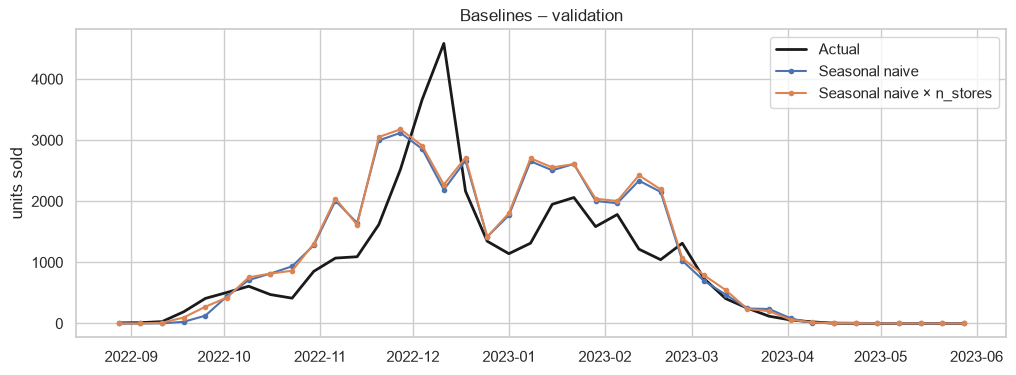

In [4]:
def seasonal_naive(past, fut):
    lag = fut.index - pd.Timedelta(weeks=52)
    return pd.Series(past.sales.reindex(lag).fillna(0).values, index=fut.index)

def seasonal_naive_stores(past, fut):
    lag = fut.index - pd.Timedelta(weeks=52)
    per_store = (past.sales / past.n_stores.replace(0, np.nan)).reindex(lag).fillna(0)
    return pd.Series(fut.n_stores.values * per_store.values, index=fut.index)

evaluate('Seasonal naive', seasonal_naive)
evaluate('Seasonal naive × n_stores', seasonal_naive_stores)
plot_val(['Seasonal naive', 'Seasonal naive × n_stores'], 'Baselines – validation')

Les deux références sont équivalentes (MSE ≈ 409 000 et ≈ 417 000) : `n_stores` vaut ≈ 55 en pleine saison les deux
années. L'erreur vient surtout du pic : copier 2021-22 le place fin novembre, alors qu'en 2022-23 il a lieu
mi-décembre et plus haut.

## 3. Méthodes classiques

Les modèles sont ajustés sur `log1p(sales)` pour stabiliser la variance, puis ramenés à l'échelle d'origine.
- **ARIMA** : d = 1 d'après les tests ADF/KPSS de l'EDA ; p et q (0 à 2) choisis par AIC.
- **SARIMAX** : un SARIMA avec s = 52 exige deux cycles complets, or le fold n'a que 50 semaines. La saisonnalité est
  donc apportée par des exogènes : `log_stores`, des termes de Fourier annuels et `pre_xmas`. Nous utilisons d = 0
  (AR(1) avec constante), car avec d = 1 la prévision est ancrée sur la dernière semaine observée, quasi nulle (test de
  sensibilité ci-dessous), et le log des ventes est stationnaire (ADF p = 0,037). Les exogènes sont choisies par AIC ;
  parmi les modèles à moins de 2 points du meilleur, nous gardons le plus simple (K = 1 + `pre_xmas`).

In [5]:
import itertools
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings('ignore', module='statsmodels')

def arima_aic_grid(y, d=1, max_p=2, max_q=2):
    rows = []
    for p, q in itertools.product(range(max_p + 1), range(max_q + 1)):
        try:
            rows.append({'order': (p, d, q), 'AIC': ARIMA(y, order=(p, d, q)).fit().aic})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)

def arima_forecast(past, fut):
    y = np.log1p(past.sales.values)
    model = ARIMA(y, order=arima_aic_grid(y).order[0]).fit()
    return pd.Series(np.expm1(model.forecast(len(fut))), index=fut.index)

display(arima_aic_grid(np.log1p(val_train.sales.values)).head())
evaluate('ARIMA', arima_forecast)

,order,AIC
0,"(1, 1, 1)",107.668065
1,"(1, 1, 2)",107.717223
2,"(2, 1, 1)",108.215800
3,"(2, 1, 0)",109.098770
4,"(2, 1, 2)",110.378400


ARIMA | MSE = 1,876,560 | RMSE = 1,370 | MAE = 907 | WAPE = 0.992


In [6]:
def sarimax_exog(df, K=1, xmas=True):
    X = pd.DataFrame({'log_stores': np.log1p(df.n_stores)}, index=df.index)
    if K:
        X = X.join(fourier_terms(df.index, K))
    if xmas:
        days_to_xmas = np.array([(pd.Timestamp(year=d.year, month=12, day=25) - d).days for d in df.index])
        X['pre_xmas'] = ((days_to_xmas >= 0) & (days_to_xmas <= 35)).astype(int)
    return X

SARIMAX_ORDER, SARIMAX_TREND = (1, 0, 0), 'c'   # AR(1) + constante, d = 0

def make_sarimax_forecast(meteo_cols=()):
    # SARIMAX ; `meteo_cols` ajoute des colonnes du tableau `meteo` (section 8.2) aux exogènes
    def exog(df):
        X = sarimax_exog(df)
        return X.join(meteo[list(meteo_cols)].reindex(df.index)) if meteo_cols else X
    def forecast(past, fut):
        model = SARIMAX(np.log1p(past.sales.values), exog=exog(past).values,
                        order=SARIMAX_ORDER, trend=SARIMAX_TREND).fit(disp=False)
        return pd.Series(np.expm1(model.forecast(len(fut), exog=exog(fut).values)), index=fut.index)
    return forecast

# Choix des exogènes par AIC (entraînement du fold uniquement)
y_fold = np.log1p(val_train.sales.values)
aic_rows = [{'K Fourier': K, 'pre_xmas': xm,
             'AIC': SARIMAX(y_fold, exog=sarimax_exog(val_train, K, xm).values, order=SARIMAX_ORDER, trend=SARIMAX_TREND).fit(disp=False).aic}
            for K in [0, 1, 2] for xm in [False, True]]
display(pd.DataFrame(aic_rows).sort_values('AIC').round(1))

sarimax_forecast = make_sarimax_forecast()
evaluate('SARIMAX', sarimax_forecast)

# Diagnostic des résidus (Ljung-Box, H0 : bruit blanc) et coefficients
fit = SARIMAX(y_fold, exog=sarimax_exog(val_train).values, order=SARIMAX_ORDER, trend=SARIMAX_TREND).fit(disp=False)
display(acorr_ljungbox(fit.resid[1:], lags=[4, 8, 12]).round(3))
display(fit.summary().tables[1])

,K Fourier,pre_xmas,AIC
4,2,False,28.0
5,2,True,28.0
3,1,True,29.2
2,1,False,30.9
1,0,True,45.4
0,0,False,49.5


SARIMAX | MSE = 307,184 | RMSE = 554 | MAE = 317 | WAPE = 0.347


,lb_stat,lb_pvalue
4,6.098,0.192
8,13.012,0.111
12,21.707,0.041


,coef,std err,z,P>|z|,[0.025,0.975]
intercept,0.5868,0.153,3.828,0.000,0.286,0.887
x1,1.2659,0.101,12.491,0.000,1.067,1.464
x2,-0.2521,0.097,-2.605,0.009,-0.442,-0.062
x3,1.4915,0.241,6.190,0.000,1.019,1.964
x4,0.4111,0.291,1.413,0.158,-0.159,0.981
ar.L1,0.4872,0.136,3.577,0.000,0.220,0.754
sigma2,0.0790,0.018,4.485,0.000,0.044,0.113


,total prévu d=1,total prévu d=0
ventes dernière semaine,,
0,11859.0,37165.0
1,23707.0,37612.0
4,56980.0,38065.0
10,117088.0,38352.0


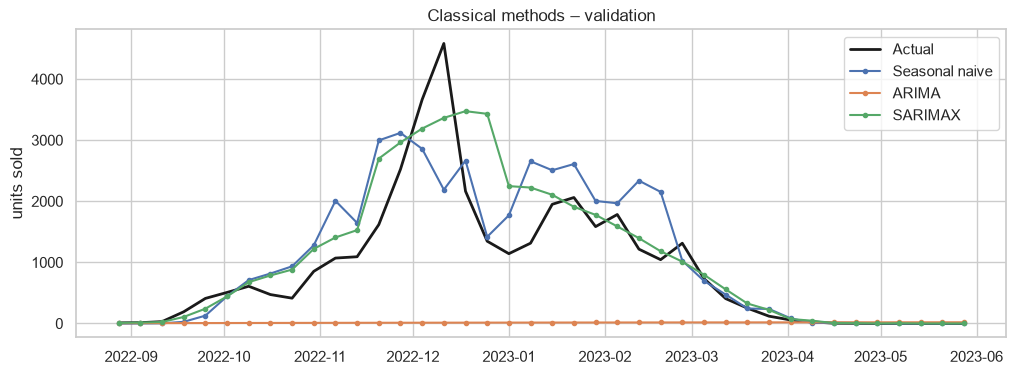

In [7]:
# Test de sensibilité : total prévu sur le test selon les ventes de la DERNIÈRE semaine connue (août 2023)
rows = []
for last in [0, 1, 4, 10]:
    h = hist.copy()
    h.iloc[-1, h.columns.get_loc('sales')] = last
    row = {'ventes dernière semaine': last}
    for label, order, trend in [('total prévu d=1', (1, 1, 0), 'n'), ('total prévu d=0', (1, 0, 0), 'c')]:
        m = SARIMAX(np.log1p(h.sales.values), exog=sarimax_exog(h).values, order=order, trend=trend).fit(disp=False)
        row[label] = np.expm1(m.forecast(len(future), exog=sarimax_exog(future).values)).clip(0).sum()
    rows.append(row)
display(pd.DataFrame(rows).set_index('ventes dernière semaine').round(0))
plot_val(['Seasonal naive', 'ARIMA', 'SARIMAX'], 'Classical methods – validation')

L'ARIMA échoue (MSE ≈ 1,9 million) : sans information saisonnière, il prolonge les ventes quasi nulles de fin d'été.
Le SARIMAX est le meilleur modèle à ce stade (≈ 307 000, −25 % par rapport au naïf saisonnier), car la courbe de
Fourier reproduit la montée et la descente de la saison ; le pic reste lissé. Le choix de d est crucial : avec d = 1,
le total prévu varie de ≈ 12 000 à ≈ 117 000 selon les ventes d'une seule semaine d'août, contre ≈ 37 000 avec d = 0.

## 4. Machine learning

Les arbres apprennent une relation entre les variables `ml_features` (1.2) et le log des ventes de chaque semaine.
Les hyperparamètres sont fixés a priori, car optimiser sur 50 semaines sur-ajusterait le fold.
- **Random Forest** : 500 arbres moyennés ; `min_samples_leaf = 2`.
- **XGBoost** : arbres construits successivement ; `max_depth = 3` et petit taux d'apprentissage.

Les modèles classiques ont ≈ 7 paramètres ; les arbres en ont des centaines pour 50 semaines : nous appliquons le test
de sur-apprentissage à partir d'ici.

Random Forest | MSE = 368,001 | RMSE = 607 | MAE = 391 | WAPE = 0.427


Random Forest | MSE train = 30,029 | MSE validation = 368,001 | ratio = 12.3


XGBoost | MSE = 371,109 | RMSE = 609 | MAE = 381 | WAPE = 0.416
XGBoost | MSE train = 7,412 | MSE validation = 371,109 | ratio = 50.1


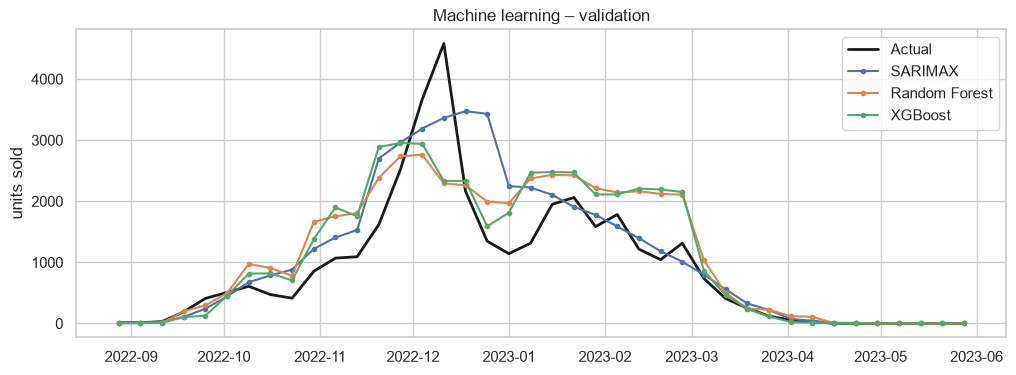

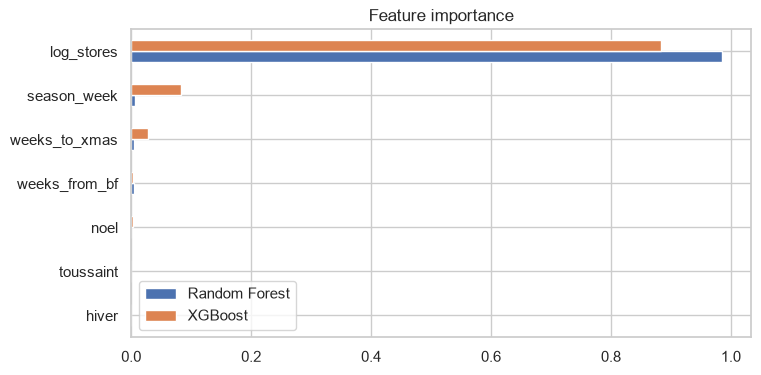

In [8]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

def ml_forecast(make_model, feature_fn=ml_features):
    def forecast(past, fut):
        model = make_model()
        model.fit(feature_fn(past), np.log1p(past.sales))
        forecast.model = model
        return pd.Series(np.expm1(model.predict(feature_fn(fut))), index=fut.index)
    return forecast

rf_forecast = ml_forecast(lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=42, n_jobs=-1))
xgb_forecast = ml_forecast(lambda: XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=3,
                                                subsample=0.8, colsample_bytree=0.8, random_state=42))
for name, fn in [('Random Forest', rf_forecast), ('XGBoost', xgb_forecast)]:
    evaluate(name, fn)
    overfit_check(name, fn)

plot_val(['SARIMAX', 'Random Forest', 'XGBoost'], 'Machine learning – validation')
pd.DataFrame({'Random Forest': rf_forecast.model.feature_importances_,
              'XGBoost': xgb_forecast.model.feature_importances_}, index=ML_FEATURES
             ).sort_values('Random Forest').plot.barh(figsize=(8, 4), title='Feature importance')
plt.show()

| Modèle | MSE validation | WAPE | MSE train | Ratio val/train |
|---|---|---|---|---|
| Random Forest | ≈ 368 000 | 42,7 % | ≈ 30 000 | 12,3 |
| XGBoost | ≈ 371 000 | 41,6 % | ≈ 7 000 | 50,1 |
| *Rappel : SARIMAX* | *≈ 307 000* | *34,7 %* | – | – |

Les deux modèles battent le naïf saisonnier (−10 % et −9 %) mais pas le SARIMAX. Ils sur-apprennent : l'erreur
d'entraînement est 12 à 50 fois plus faible que celle de validation, car les arbres reproduisent la saison 2021-22 (pic
fin novembre, creux de Noël) et l'appliquent à 2022-23. `log_stores` porte presque toute l'importance. La
régularisation est traitée en 8.1.

## 5. Deep learning

- **LSTM** : un LSTM classique prédit la semaine suivante à partir des ventes passées et reproduirait l'échec de
  l'ARIMA. Le réseau lit donc la séquence des variables connues à l'avance et produit les ventes de chaque semaine :
  fenêtres de 40 semaines (l'horizon), 16 neurones, 300 époques, moyenne de 5 graines pour la stabilité. Une grille
  (fenêtre × neurones) vérifie que le résultat ne dépend pas d'un réglage particulier.
- **TFT et N-HiTS** (`pytorch-forecasting`) : série unique, encodeur de 4 semaines puis variables lisses sur les
  semaines à prévoir, cible en log, perte MAE, moyenne de 3 graines. Le TFT intègre nativement les variables connues à
  l'avance ; nous l'entraînons sur des horizons de 1 à 40 semaines pour multiplier les fenêtres. Le N-HiTS impose des
  fenêtres de longueur fixe (4 + 40 semaines).

In [9]:
import torch
import torch.nn as nn
torch.set_num_threads(4)

class LSTMNet(nn.Module):
    def __init__(self, n_features, hidden, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)     # actif seulement en mode entraînement
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):                      # x : (batch, semaines, features)
        return self.head(self.dropout(self.lstm(x)[0])).squeeze(-1)

def make_lstm_forecast(window=40, hidden=16, epochs=300, n_seeds=5, lr=0.01, weight_decay=1e-4,
                       dropout=0.0, feature_fn=ml_features):
    def forecast(past, fut):
        X_past, X_fut = feature_fn(past), feature_fn(fut)
        mu, sd = X_past.mean(), X_past.std().replace(0, 1)
        X_past = ((X_past - mu) / sd).values.astype('float32')
        X_fut = ((X_fut - mu) / sd).values.astype('float32')
        y = np.log1p(past.sales.values).astype('float32')
        y_mu, y_sd = y.mean(), y.std()
        y_std = (y - y_mu) / y_sd
        starts = range(len(y) - window + 1)    # fenêtres glissantes de `window` semaines
        X_win = torch.tensor(np.stack([X_past[s:s + window] for s in starts]))
        y_win = torch.tensor(np.stack([y_std[s:s + window] for s in starts]))
        preds = []
        for seed in range(n_seeds):
            torch.manual_seed(seed)
            net = LSTMNet(X_past.shape[1], hidden, dropout)
            opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
            for _ in range(epochs):
                opt.zero_grad()
                ((net(X_win) - y_win) ** 2).mean().backward()
                opt.step()
            net.eval()
            with torch.no_grad():
                preds.append(net(torch.tensor(X_fut)[None])[0].numpy())
        return pd.Series(np.expm1(np.mean(preds, axis=0) * y_sd + y_mu), index=fut.index)
    return forecast

lstm_forecast = make_lstm_forecast()
evaluate('LSTM', lstm_forecast)
overfit_check('LSTM', lstm_forecast)

# Sensibilité aux hyperparamètres (longueur des fenêtres × taille de la couche cachée)
sens = [{'fenêtre': win, 'neurones': hid,
         'MSE': metrics(y_val, make_lstm_forecast(window=win, hidden=hid)(val_train, val_future.drop(columns='sales')).clip(lower=0))['MSE']}
        for win in [13, 26, 40] for hid in [8, 16, 32]]
pd.DataFrame(sens).pivot(index='fenêtre', columns='neurones', values='MSE').style.format('{:,.0f}')

LSTM | MSE = 362,768 | RMSE = 602 | MAE = 362 | WAPE = 0.396


LSTM | MSE train = 23,154 | MSE validation = 362,768 | ratio = 15.7


neurones,8,16,32
fenêtre,,,
13,"398,963","395,068","390,106"
26,"401,314","372,017","378,054"
40,"405,715","362,768","364,182"


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\loops\training_epoch_loop.py:500: ReduceLROnPlateau conditioned on metric val_loss which is not available but strict is set to `False`. Skipping learning rate update.


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\logger_connector\logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


TFT | MSE = 442,843 | RMSE = 665 | MAE = 416 | WAPE = 0.455
  fenêtres d'entraînement : 89


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\loops\training_epoch_loop.py:500: ReduceLROnPlateau conditioned on metric val_loss which is not available but strict is set to `False`. Skipping learning rate update.


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


N-HiTS | MSE = 1,890,247 | RMSE = 1,375 | MAE = 910 | WAPE = 0.995
  fenêtres d'entraînement : 7


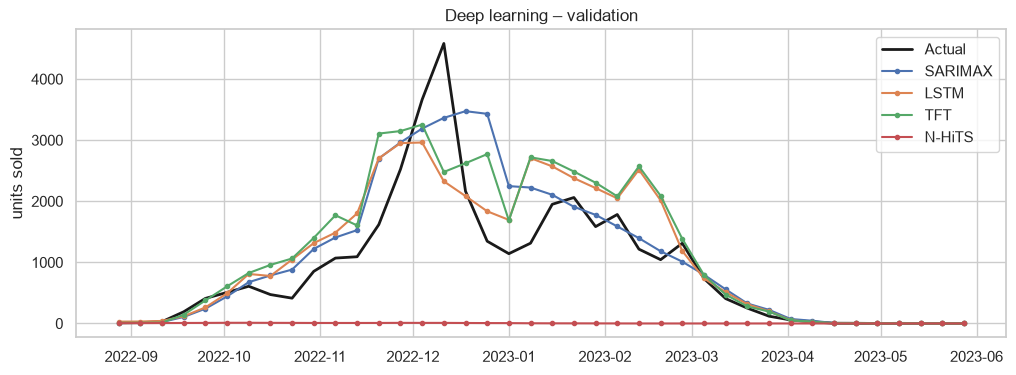

In [10]:
import logging
import lightning.pytorch as pl
from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer, NHiTS
from pytorch_forecasting.metrics import MAE
from pytorch_forecasting.data import TorchNormalizer
for logger_name in ['lightning', 'lightning.pytorch', 'pytorch_lightning', 'lightning_fabric']:
    logging.getLogger(logger_name).setLevel(logging.ERROR)

def pf_frame(past, fut):
    df = pd.concat([past, fut.assign(sales=0.0)])   # ventes futures inconnues : remplies par 0, jamais lues
    X = ml_features_smooth(df)
    X['log_sales'] = np.log1p(df.sales.values)
    X['time_idx'] = np.arange(len(X))
    X['series'] = 'bonnet'
    return X.reset_index(drop=True)

def make_pf_forecast(kind, encoder_length=4, epochs=60, n_seeds=3, hidden=16, lr=0.01):
    def forecast(past, fut):
        df, H = pf_frame(past, fut), len(fut)
        fixed = kind == 'nhits'   # N-HiTS impose des fenêtres de longueur fixe
        train_ds = TimeSeriesDataSet(
            df.iloc[:len(past)], time_idx='time_idx', target='log_sales', group_ids=['series'],
            max_encoder_length=encoder_length, min_encoder_length=encoder_length if fixed else 2,
            max_prediction_length=H, min_prediction_length=H if fixed else 1,
            time_varying_known_reals=ML_FEATURES_SMOOTH, time_varying_unknown_reals=['log_sales'],
            target_normalizer=TorchNormalizer(), add_relative_time_idx=not fixed)
        forecast.n_windows = len(train_ds)
        pred_ds = TimeSeriesDataSet.from_dataset(train_ds, df, predict=True, stop_randomization=True)
        preds = []
        for seed in range(n_seeds):
            pl.seed_everything(seed, verbose=False)
            if kind == 'tft':
                model = TemporalFusionTransformer.from_dataset(
                    train_ds, hidden_size=hidden, attention_head_size=1, dropout=0.1,
                    hidden_continuous_size=8, loss=MAE(), learning_rate=lr, log_interval=-1)
            else:
                model = NHiTS.from_dataset(train_ds, hidden_size=hidden, dropout=0.1, loss=MAE(),
                                           learning_rate=lr, log_interval=-1)
            trainer = pl.Trainer(max_epochs=epochs, accelerator='cpu', enable_progress_bar=False, logger=False,
                                 enable_checkpointing=False, enable_model_summary=False, gradient_clip_val=0.1)
            trainer.fit(model, train_dataloaders=train_ds.to_dataloader(train=True, batch_size=16, num_workers=0))
            out = model.predict(pred_ds.to_dataloader(train=False, batch_size=1, num_workers=0), mode='prediction')
            preds.append(np.asarray(out).reshape(-1)[:H])
        return pd.Series(np.expm1(np.mean(preds, axis=0)), index=fut.index)
    return forecast

tft_forecast, nhits_forecast = make_pf_forecast('tft'), make_pf_forecast('nhits')
for name, fn in [('TFT', tft_forecast), ('N-HiTS', nhits_forecast)]:
    evaluate(name, fn)
    print('  fenêtres d\'entraînement :', fn.n_windows)
plot_val(['SARIMAX', 'LSTM', 'TFT', 'N-HiTS'], 'Deep learning – validation')

| Modèle | MSE validation | WAPE | Fenêtres d'entraînement |
|---|---|---|---|
| LSTM | ≈ 363 000 | 39,6 % | 11 |
| TFT | ≈ 443 000 | 45,5 % | 89 |
| N-HiTS | ≈ 1 890 000 | 99,5 % | 7 |

Le LSTM bat le naïf saisonnier (−11 %) et sa MSE reste stable sur la grille (≈ 363 000 à 406 000), mais il sur-apprend
(ratio 15,7) en copiant le profil de 2021-22. Le TFT ne bat pas la référence et le N-HiTS prévoit ≈ 0 : avec une seule
saison d'entraînement, leurs nombreux paramètres n'ont rien à apprendre, et les fenêtres fixes du N-HiTS ne laissent que
7 exemples. Un essai global sur les 55 magasins (hors notebook) ne les améliore pas (N-HiTS ≈ 1 575 000, TFT ≈ 507 000).

## 6. Modèle préentraîné : Chronos-2

Chronos-2 (Amazon, 2025) est préentraîné sur un grand corpus de séries et utilisé en **zéro-shot** : aucun
entraînement sur nos données, donc pas de test de sur-apprentissage. Contexte = tout l'historique avant la prévision,
prévision = médiane, cible = ventes brutes (le modèle normalise lui-même). Quatre variantes :
historique seul ; avec les variables lisses connues à l'avance ; par magasin (55 séries additionnées) ; par magasin avec
**cross-learning**, où le modèle prévoit les 55 magasins ensemble en s'appuyant sur les autres séries.

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2 | MSE = 1,110,671 | RMSE = 1,054 | MAE = 658 | WAPE = 0.719


Chronos-2 + covariables | MSE = 376,473 | RMSE = 614 | MAE = 388 | WAPE = 0.425


Chronos-2 par magasin | MSE = 363,825 | RMSE = 603 | MAE = 367 | WAPE = 0.402


Chronos-2 par magasin + cross-learning | MSE = 356,046 | RMSE = 597 | MAE = 363 | WAPE = 0.397


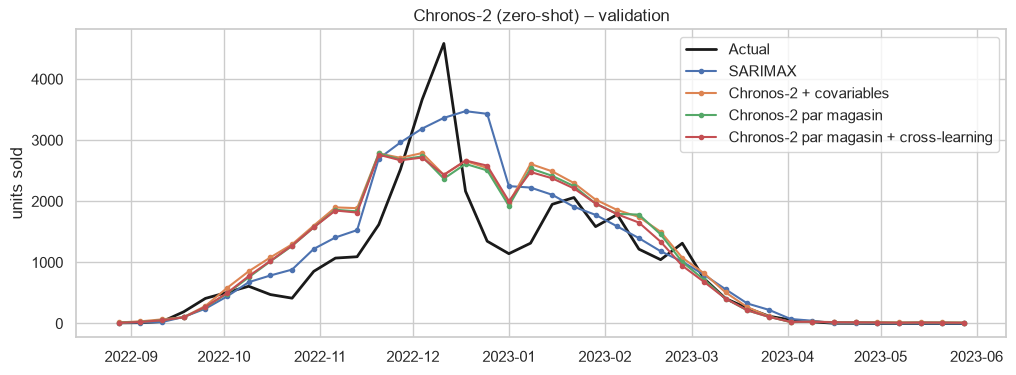

In [11]:
from chronos import Chronos2Pipeline
chronos = Chronos2Pipeline.from_pretrained('amazon/chronos-2', device_map='cpu')   # téléchargé au premier appel

def make_chronos_forecast(covariates):
    def forecast(past, fut):
        context = pd.DataFrame({'item_id': 'bonnet', 'timestamp': past.index, 'target': past.sales.values})
        future_cov = None
        if covariates:
            context = pd.concat([context, ml_features_smooth(past).reset_index(drop=True)], axis=1)
            future_cov = pd.concat([pd.DataFrame({'item_id': 'bonnet', 'timestamp': fut.index}),
                                    ml_features_smooth(fut).reset_index(drop=True)], axis=1)
        out = chronos.predict_df(context, future_df=future_cov, prediction_length=len(fut), quantile_levels=[0.5])
        return pd.Series(out['predictions'].values, index=fut.index)
    return forecast

def make_chronos_store_forecast(cross_learning, meteo_cols=()):
    feature_fn = features_with(meteo_cols)
    def forecast(past, fut):
        cov_past, cov_fut = feature_fn(past).reset_index(drop=True), feature_fn(fut).reset_index(drop=True)
        context, future_cov = [], []
        for bu in store_sales.columns:
            y = store_sales.loc[past.index, bu].values
            if y.sum() == 0:
                continue
            context.append(pd.concat([pd.DataFrame({'item_id': str(bu), 'timestamp': past.index, 'target': y}), cov_past], axis=1))
            future_cov.append(pd.concat([pd.DataFrame({'item_id': str(bu), 'timestamp': fut.index}), cov_fut], axis=1))
        # batch_size = 512 : les 55 magasins (cible + covariables) sont traités dans le même lot
        out = chronos.predict_df(pd.concat(context), future_df=pd.concat(future_cov), prediction_length=len(fut),
                                 quantile_levels=[0.5], cross_learning=cross_learning, batch_size=512)
        total = out.assign(pred=out['predictions'].clip(lower=0)).groupby('timestamp').pred.sum()   # somme des magasins
        return pd.Series(total.reindex(fut.index).values, index=fut.index)
    return forecast

chronos_cross_forecast = make_chronos_store_forecast(cross_learning=True)
for name, fn in [('Chronos-2', make_chronos_forecast(covariates=False)),
                 ('Chronos-2 + covariables', make_chronos_forecast(covariates=True)),
                 ('Chronos-2 par magasin', make_chronos_store_forecast(cross_learning=False)),
                 ('Chronos-2 par magasin + cross-learning', chronos_cross_forecast)]:
    evaluate(name, fn)
plot_val(['SARIMAX', 'Chronos-2 + covariables', 'Chronos-2 par magasin', 'Chronos-2 par magasin + cross-learning'],
         'Chronos-2 (zero-shot) – validation')

| Modèle | MSE validation | WAPE |
|---|---|---|
| Chronos-2 (historique seul) | ≈ 1 111 000 | 71,9 % |
| Chronos-2 + covariables | ≈ 376 000 | 42,5 % |
| Chronos-2 par magasin | ≈ 364 000 | 40,2 % |
| **Chronos-2 par magasin + cross-learning** | **≈ 356 000** | **39,7 %** |

Sur l'historique seul, Chronos-2 échoue, car son contexte ne contient qu'une saison terminée par l'été. Avec les
variables connues à l'avance, il bat le naïf saisonnier sans entraînement et en quelques secondes ; la prévision par
magasin (−3 %) puis le cross-learning (−2 %) l'améliorent encore. Il reste derrière les modèles entraînés sur nos
données, car il n'a jamais vu de produit à pic de Noël (essai en log hors notebook : ≈ 420 000 et ≈ 682 000).

## 7. Modèles par magasin

Chaque magasin a son propre niveau de ventes (EDA : corrélation de 0,85 entre saisons). Nous prévoyons donc chaque
magasin puis **additionnons les 55 prévisions**. Un magasin sans vente sur l'entraînement reçoit une prévision nulle.
- **XGBoost par magasin** : un XGBoost régularisé (hyperparamètres de 8.1) par magasin, variables lisses. Variante avec
  un indicateur d'activité du magasin (connu sur le test : une ligne n'existe que s'il vend), prévision forcée à 0
  quand il vaut 0.
- **LSTM global avec embedding** : un seul LSTM sur les 55 magasins, car un LSTM par magasin aurait encore moins de
  données. Chaque magasin reçoit un **embedding** (vecteur de 4 nombres appris) qui capture son niveau ; mêmes
  séquences que le LSTM de 5, 16 neurones, dropout 0,3, weight decay 1e-3, mini-lots de 128, 150 époques, 3 graines.

In [12]:
XGB_REG = dict(n_estimators=300, learning_rate=0.03, max_depth=2, min_child_weight=5,
               reg_lambda=5, reg_alpha=1, subsample=0.8, colsample_bytree=0.8, random_state=42)

def make_store_forecast(use_active=False, meteo_cols=(), half_life=None):
    # XGBoost régularisé par magasin ; `half_life` pondère les semaines récentes (section 8.3)
    feature_fn = features_with(meteo_cols)
    feats = ML_FEATURES_SMOOTH + list(meteo_cols) + (['active'] if use_active else [])
    monotone = tuple(1 if f in ('log_stores', 'active') else 0 for f in feats)
    def forecast(past, fut):
        X_past, X_fut = feature_fn(past), feature_fn(fut)
        weights = 0.5 ** (np.arange(len(past))[::-1] / half_life) if half_life else None
        total = np.zeros(len(fut))
        for bu in store_sales.columns:
            y = np.log1p(store_sales.loc[past.index, bu].values)
            if y.sum() == 0:
                continue
            Xp, Xf = X_past, X_fut
            if use_active:
                Xp = X_past.assign(active=store_active.loc[past.index, bu].values)
                Xf = X_fut.assign(active=store_active.loc[fut.index, bu].values)
            model = XGBRegressor(**XGB_REG, monotone_constraints=monotone, n_jobs=1)
            model.fit(Xp[feats], y, sample_weight=weights)
            pred = np.expm1(model.predict(Xf[feats])).clip(0)
            total += pred * Xf.active.values if use_active else pred   # pas de ligne = pas de vente
        return pd.Series(total, index=fut.index)
    return forecast

store_forecast = make_store_forecast()
for name, fn in [('XGBoost par magasin', store_forecast),
                 ('XGBoost par magasin + activité', make_store_forecast(use_active=True))]:
    evaluate(name, fn)
    overfit_check(name, fn)

XGBoost par magasin | MSE = 298,265 | RMSE = 546 | MAE = 317 | WAPE = 0.346


XGBoost par magasin | MSE train = 62,049 | MSE validation = 298,265 | ratio = 4.8


XGBoost par magasin + activité | MSE = 313,878 | RMSE = 560 | MAE = 322 | WAPE = 0.352


XGBoost par magasin + activité | MSE train = 69,567 | MSE validation = 313,878 | ratio = 4.5


LSTM global + embedding | MSE = 327,890 | RMSE = 573 | MAE = 331 | WAPE = 0.361


LSTM global + embedding | MSE train = 16,343 | MSE validation = 327,890 | ratio = 20.1


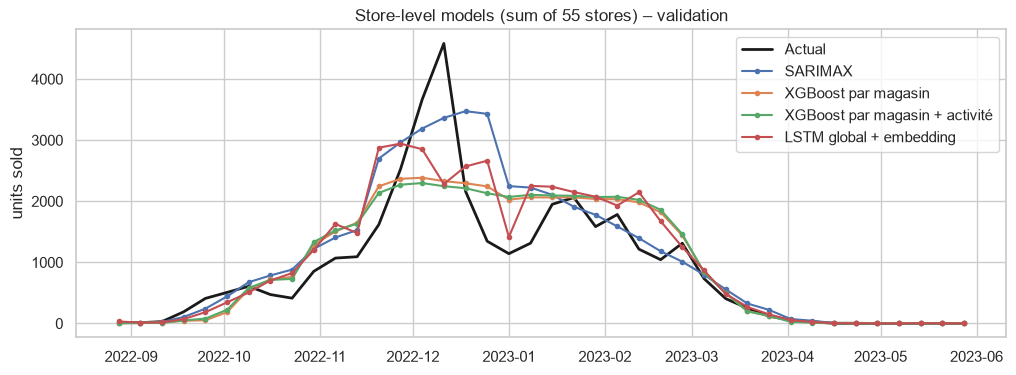

In [13]:
class StoreLSTM(nn.Module):
    def __init__(self, n_stores, n_features, emb_dim, hidden, dropout):
        super().__init__()
        self.embedding = nn.Embedding(n_stores, emb_dim)   # un vecteur appris par magasin
        self.lstm = nn.LSTM(n_features + emb_dim, hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x, store):                           # x : (batch, semaines, features)
        e = self.embedding(store)[:, None, :].expand(-1, x.shape[1], -1)
        return self.head(self.dropout(self.lstm(torch.cat([x, e], dim=-1))[0])).squeeze(-1)

def make_store_lstm_forecast(epochs, meteo_cols=(), window=40, emb_dim=4, hidden=16, dropout=0.3, n_seeds=3,
                             lr=0.01, weight_decay=1e-3):
    feature_fn = features_with(meteo_cols)
    def forecast(past, fut):
        X_past, X_fut = feature_fn(past), feature_fn(fut)
        mu, sd = X_past.mean(), X_past.std().replace(0, 1)
        X_past = ((X_past - mu) / sd).values.astype('float32')
        X_fut = ((X_fut - mu) / sd).values.astype('float32')
        Y = np.log1p(store_sales.loc[past.index].values).astype('float32')   # (semaines, magasins)
        Y = Y[:, Y.sum(axis=0) > 0]                                          # magasins avec au moins une vente
        n_stores = Y.shape[1]
        y_mu, y_sd = Y.mean(), Y.std()
        Y = (Y - y_mu) / y_sd
        starts = range(len(Y) - window + 1)
        X_win = torch.tensor(np.stack([X_past[s:s + window] for s in starts for _ in range(n_stores)]))
        y_win = torch.tensor(np.stack([Y[s:s + window, j] for s in starts for j in range(n_stores)]))
        s_win = torch.tensor([j for _ in starts for j in range(n_stores)])
        preds = []
        for seed in range(n_seeds):
            torch.manual_seed(seed)
            net = StoreLSTM(n_stores, X_past.shape[1], emb_dim, hidden, dropout)
            opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
            for _ in range(epochs):
                perm = torch.randperm(len(X_win))
                for b in range(0, len(X_win), 128):
                    idx = perm[b:b + 128]
                    opt.zero_grad()
                    ((net(X_win[idx], s_win[idx]) - y_win[idx]) ** 2).mean().backward()
                    opt.step()
            net.eval()
            with torch.no_grad():
                x = torch.tensor(X_fut)[None].expand(n_stores, -1, -1)
                log_pred = net(x, torch.arange(n_stores)).numpy() * y_sd + y_mu    # (magasins, semaines)
            preds.append(np.expm1(log_pred).clip(0).sum(axis=0))                  # somme des magasins
        return pd.Series(np.mean(preds, axis=0), index=fut.index)
    return forecast

store_lstm_forecast = make_store_lstm_forecast(epochs=150)
evaluate('LSTM global + embedding', store_lstm_forecast)
overfit_check('LSTM global + embedding', store_lstm_forecast)
plot_val(['SARIMAX', 'XGBoost par magasin', 'XGBoost par magasin + activité', 'LSTM global + embedding'],
         'Store-level models (sum of 55 stores) – validation')

| Modèle | MSE train | MSE validation | Ratio | WAPE |
|---|---|---|---|---|
| **XGBoost par magasin** | ≈ 62 000 | **≈ 298 000** | 4,8 | 34,6 % |
| XGBoost par magasin + activité | ≈ 70 000 | ≈ 314 000 | 4,5 | 35,2 % |
| LSTM global + embedding (150 époques) | ≈ 16 000 | ≈ 328 000 | 20,1 | 36,1 % |

Le XGBoost par magasin bat le SARIMAX (−3 %), car chaque modèle apprend le niveau de son magasin ; sa prévision garde
toutefois une forme en plateau sans le pic de décembre. L'indicateur d'activité n'aide pas : en pleine saison tous les
magasins sont actifs, il vaut 1 précisément là où se trouvent les erreurs. Le LSTM global mémorise (ratio 20) : il est
réentraîné plus court en 8.1.

## 8. Optimisations

Toutes les pistes d'amélioration, définies avant de voir leurs résultats :

1. **Régularisation** (8.1) des modèles qui sur-apprennent ;
2. **Données externes** (8.2) : météo de Paris et vacances d'hiver des zones A et B ;
3. **Météo, vacances et pondération des semaines récentes** (8.3) ajoutées aux meilleurs modèles ;
4. **Robustesse sur plusieurs folds** (8.4), car un seul fold de validation peut tromper.

### 8.1 Régularisation

- **Random Forest** : variables lisses, `min_samples_leaf = 6` et `max_depth = 4`.
- **XGBoost** : variables lisses, `max_depth = 2`, `min_child_weight = 5`, pénalités L2 (5) et L1 (1), contrainte
  monotone croissante sur `log_stores` (plus de magasins actifs ne peut pas faire baisser la prévision).
- **LSTM** : variables lisses, 8 neurones, dropout 0,3, weight decay 1e-3, 150 époques au lieu de 300.
- **LSTM global** : 60 époques au lieu de 150, car avec 605 séquences en mini-lots une époque compte 5 mises à jour des
  poids. Ce réglage a été choisi après avoir vu le résultat à 150 époques : son score est légèrement optimiste.

Random Forest régularisé | MSE = 357,749 | RMSE = 598 | MAE = 361 | WAPE = 0.395


Random Forest régularisé | MSE train = 93,195 | MSE validation = 357,749 | ratio = 3.8


XGBoost régularisé | MSE = 319,429 | RMSE = 565 | MAE = 339 | WAPE = 0.370


XGBoost régularisé | MSE train = 62,255 | MSE validation = 319,429 | ratio = 5.1


LSTM régularisé | MSE = 324,968 | RMSE = 570 | MAE = 304 | WAPE = 0.332


LSTM régularisé | MSE train = 58,458 | MSE validation = 324,968 | ratio = 5.6


LSTM global + embedding (60 ép.) | MSE = 296,569 | RMSE = 545 | MAE = 302 | WAPE = 0.330


LSTM global + embedding (60 ép.) | MSE train = 35,806 | MSE validation = 296,569 | ratio = 8.3


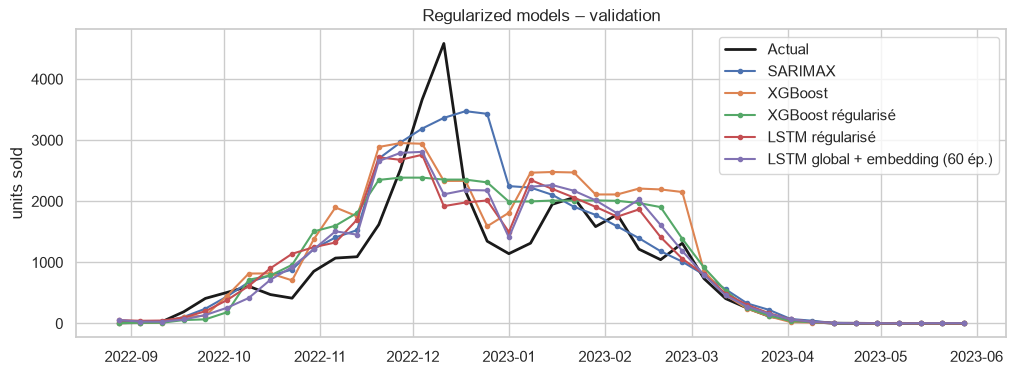

,MSE train,MSE validation,ratio val / train
Random Forest,"30,029","368,001",12.3
Random Forest régularisé,"93,195","357,749",3.8
XGBoost,"7,412","371,109",50.1
XGBoost régularisé,"62,255","319,429",5.1
LSTM,"23,154","362,768",15.7
LSTM régularisé,"58,458","324,968",5.6
LSTM global + embedding,"16,343","327,890",20.1
LSTM global + embedding (60 ép.),"35,806","296,569",8.3


In [14]:
rf_reg_forecast = ml_forecast(lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=6, max_depth=4,
                                                            random_state=42, n_jobs=-1), feature_fn=ml_features_smooth)
monotone = tuple(1 if f == 'log_stores' else 0 for f in ML_FEATURES_SMOOTH)
xgb_reg_forecast = ml_forecast(lambda: XGBRegressor(**XGB_REG, monotone_constraints=monotone), feature_fn=ml_features_smooth)
lstm_reg_forecast = make_lstm_forecast(hidden=8, dropout=0.3, weight_decay=1e-3, epochs=150, feature_fn=ml_features_smooth)
store_lstm_short_forecast = make_store_lstm_forecast(epochs=60)

for name, fn in [('Random Forest régularisé', rf_reg_forecast), ('XGBoost régularisé', xgb_reg_forecast),
                 ('LSTM régularisé', lstm_reg_forecast), ('LSTM global + embedding (60 ép.)', store_lstm_short_forecast)]:
    evaluate(name, fn)
    overfit_check(name, fn)

plot_val(['SARIMAX', 'XGBoost', 'XGBoost régularisé', 'LSTM régularisé', 'LSTM global + embedding (60 ép.)'],
         'Regularized models – validation')
overfit_table(['Random Forest', 'Random Forest régularisé', 'XGBoost', 'XGBoost régularisé', 'LSTM', 'LSTM régularisé',
               'LSTM global + embedding', 'LSTM global + embedding (60 ép.)'])

| Modèle | Ratio val/train avant → après | MSE validation avant → après |
|---|---|---|
| Random Forest | 12,3 → 3,8 | ≈ 368 000 → ≈ 358 000 |
| XGBoost | 50,1 → 5,1 | ≈ 371 000 → **≈ 319 000** (−14 %) |
| LSTM | 15,7 → 5,6 | ≈ 363 000 → ≈ 325 000 (−10 %) |
| LSTM global + embedding | 20,1 → 8,3 | ≈ 328 000 → **≈ 297 000** (−9 %) |

La régularisation réduit fortement le sur-apprentissage et améliore la validation. Avec les variables lisses, les
modèles s'appuient sur la courbe annuelle plutôt que sur la position exacte de chaque semaine. Le gain reste faible
pour le Random Forest, trop contraint, qui produit un plateau (≈ 2 200 unités) sans le pic.

### 8.2 Données externes : météo et vacances

**Météo.** API Historical Weather d'**Open-Meteo** (`archive-api.open-meteo.com/v1/archive`), issue de la **réanalyse
ERA5** de Copernicus (ECMWF), point **Paris (48,8566° N ; 2,3522° E)**, du 01/09/2021 au 01/06/2024 : température
moyenne à 2 m et chutes de neige, agrégées par semaine Decathlon. Licence CC BY 4.0. Cache :
`donnees_externes/meteo_paris_open_meteo.csv`. La semaine record (4 582 unités, 11/12/2022) coïncide avec une vague de
froid. Variables dérivées (météo « enrichie ») :
- `hdd` : degrés-jours de froid, max(0 ; 10 °C − température) : nuls en semaine douce, ils bornent l'effet du froid ;
- `cold_week` : température moyenne < 2 °C ; `snow` : neige cumulée ;
- `first_cold` : première semaine de la saison sous 5 °C, car la première vague de froid déclenche les achats.

**Météo régionale.** Les magasins vont de Laon à Nevers (jusqu'à 216 km de Paris, jusqu'à 3,2 °C d'écart hebdomadaire).
Coordonnées de la commune de chaque magasin : **API Geocoding d'Open-Meteo** (`geocoding-api.open-meteo.com/v1/search`) ;
météo de chaque commune : même API Historical Weather (48 communes). La température et la neige **régionales** sont la
moyenne des communes pondérée par les ventes de chaque magasin sur l'entraînement du fold (sept. 2021 → août 2022), pour
représenter le froid ressenti par l'ensemble des clients ; les variables enrichies sont recalculées sur cette moyenne
(suffixe `_reg`). Cache : `donnees_externes/meteo_communes_magasins.csv`.

**Vacances.** Calendrier scolaire officiel (**data.education.gouv.fr**, jeu `fr-en-calendrier-scolaire`) : `hiver_ab`
= 1 si la semaine chevauche les vacances d'hiver de la zone A ou B (la zone C est déjà dans les variables de base).
Cache : `donnees_externes/vacances_hiver_zones.csv`.

**Limites.** Sur le test, la météo utilisée est la météo **observée**, inconnue au moment d'une vraie prévision.
Vérifier aussi que le règlement Kaggle autorise les données externes.

In [15]:
METEO_URL = ('https://archive-api.open-meteo.com/v1/archive?latitude=48.8566&longitude=2.3522'
             '&start_date=2021-09-01&end_date=2024-06-01&daily=temperature_2m_mean,snowfall_sum&timezone=Europe%2FParis')
VAC_URL = ('https://data.education.gouv.fr/api/explore/v2.1/catalog/datasets/fr-en-calendrier-scolaire/records'
           '?select=zones,annee_scolaire,start_date,end_date&where=description%20like%20%22Hiver%22%20and%20annee_scolaire'
           '%20in%20(%222021-2022%22,%222022-2023%22,%222023-2024%22)&group_by=zones,annee_scolaire,start_date,end_date&limit=100')
METEO_CSV = Path('../donnees_externes/meteo_paris_open_meteo.csv')
VAC_CSV = Path('../donnees_externes/vacances_hiver_zones.csv')

def fetch_json(url, key):
    with urllib.request.urlopen(url, timeout=60) as response:
        return pd.DataFrame(json.load(response)[key])

if METEO_CSV.exists():
    meteo_daily = pd.read_csv(METEO_CSV, parse_dates=['time'], index_col='time')
else:
    meteo_daily = fetch_json(METEO_URL, 'daily')
    meteo_daily = meteo_daily.assign(time=pd.to_datetime(meteo_daily.time)).set_index('time')
    METEO_CSV.parent.mkdir(exist_ok=True)
    meteo_daily.to_csv(METEO_CSV)
if VAC_CSV.exists():
    vacances = pd.read_csv(VAC_CSV, parse_dates=['start_date', 'end_date'])
else:
    vacances = fetch_json(VAC_URL, 'results')
    for col in ['start_date', 'end_date']:   # dates publiées en UTC : conversion en date locale
        vacances[col] = pd.to_datetime(vacances[col]).dt.tz_convert('Europe/Paris').dt.tz_localize(None).dt.normalize()
    vacances = vacances[vacances.zones.isin(['Zone A', 'Zone B', 'Zone C'])].sort_values(['annee_scolaire', 'zones'])
    vacances.to_csv(VAC_CSV, index=False)

# Semaine Decathlon : du dimanche (`date`) au samedi suivant
meteo = (meteo_daily.resample('W-SAT', label='left', closed='right')
         .agg({'temperature_2m_mean': 'mean', 'snowfall_sum': 'sum'})
         .rename(columns={'temperature_2m_mean': 'temp_mean', 'snowfall_sum': 'snow'}))
meteo.index = meteo.index + pd.Timedelta(days=1)

def enrich(m):
    # degrés-jours de froid, semaine froide, première semaine < 5 °C de chaque saison
    out = pd.DataFrame({'hdd': (10 - m.temp_mean).clip(lower=0), 'cold_week': (m.temp_mean < 2).astype(int)}, index=m.index)
    cold_weeks = m.index[m.temp_mean < 5]
    first = pd.Series(cold_weeks).groupby(np.where(cold_weeks.month >= 8, cold_weeks.year, cold_weeks.year - 1)).min()
    out['first_cold'] = m.index.isin(first).astype(int)
    return out

meteo = meteo.join(enrich(meteo))

# Météo régionale : communes des magasins, moyenne pondérée par les ventes de l'entraînement du fold
COMMUNES_CSV = Path('../donnees_externes/meteo_communes_magasins.csv')
GEO_NAME = {'PHITIVIERS': 'Pithiviers', 'Paris La Défense': 'Puteaux', 'DAMMARIE LES LYS CEDEX': 'Dammarie-les-Lys',
            'SAINT MAXIMIN': 'Saint-Maximin', 'CLAYE SOUILLY': 'Claye-Souilly', 'MANTES BUCHELAY': 'Buchelay',
            'Saint Maur': 'Saint-Maur-des-Fossés', 'STE GENEVIEVE DES BOIS': 'Sainte-Geneviève-des-Bois',
            'BRY SUR MARNE': 'Bry-sur-Marne', 'BRETIGNY SUR ORGE': 'Brétigny-sur-Orge', 'Brétigny-sur-Orge': 'Brétigny-sur-Orge', 'SAINT DOULCHARD': 'Saint-Doulchard',
            'ROMORANTIN LANTHENAY': 'Romorantin-Lanthenay', 'VARENNES SUR SEINE': 'Varennes-sur-Seine',
            'VILLEBON-SUR-YVETTE': 'Villebon-sur-Yvette', 'PONTAULT COMBAULT': 'Pontault-Combault', "L'ISLE ADAM": "L'Isle-Adam",
            'LE CHESNAY': 'Le Chesnay', 'SAINT-DENIS': 'Saint-Denis', 'Croissy Beaubourg': 'Croissy-Beaubourg'}
REGIONS = ['Île-de-France', 'Hauts-de-France', 'Centre-Val de Loire', 'Bourgogne-Franche-Comté']
stores = pd.read_csv(DATA_DIR / 'stores_location.csv')
stores['commune'] = [GEO_NAME.get(city, city.title()) for city in stores.city]
if COMMUNES_CSV.exists():
    communes_daily = pd.read_csv(COMMUNES_CSV, parse_dates=['time'])
else:
    coords = []
    for commune in stores.commune.unique():
        hits = fetch_json('https://geocoding-api.open-meteo.com/v1/search?count=10&language=fr&countryCode=FR&name='
                          + urllib.parse.quote(commune), 'results')
        hit = hits[hits.admin1.isin(REGIONS)].iloc[0] if hits.admin1.isin(REGIONS).any() else hits.iloc[0]
        coords.append((commune, hit.latitude, hit.longitude))
    # une seule requête pour toutes les communes (l'API limite le nombre d'appels)
    url = METEO_URL.replace('latitude=48.8566&longitude=2.3522',
                            'latitude=' + ','.join(f'{lat:.4f}' for _, lat, _ in coords)
                            + '&longitude=' + ','.join(f'{lon:.4f}' for _, _, lon in coords))
    with urllib.request.urlopen(url, timeout=120) as response:
        answers = json.load(response)
    communes_daily = pd.concat([pd.DataFrame(a['daily']).assign(commune=c, latitude=lat, longitude=lon)
                                for (c, lat, lon), a in zip(coords, answers)]).assign(time=lambda d: pd.to_datetime(d.time))
    communes_daily.to_csv(COMMUNES_CSV, index=False)

def to_weekly(daily):
    out = (daily.set_index('time').resample('W-SAT', label='left', closed='right')
           .agg({'temperature_2m_mean': 'mean', 'snowfall_sum': 'sum'})
           .rename(columns={'temperature_2m_mean': 'temp_mean', 'snowfall_sum': 'snow'}))
    out.index = out.index + pd.Timedelta(days=1)
    return out

commune_weekly = {commune: to_weekly(d) for commune, d in communes_daily.groupby('commune')}
store_commune = stores.set_index('bu').commune
sales_weights = store_sales.loc[val_train.index].sum() / store_sales.loc[val_train.index].values.sum()
regional = sum(commune_weekly[store_commune[bu]][['temp_mean', 'snow']] * sales_weights[bu] for bu in store_sales.columns)
meteo = meteo.join(regional.join(enrich(regional)).add_suffix('_reg'))
ab = vacances[vacances.zones.isin(['Zone A', 'Zone B'])]
meteo['hiver_ab'] = np.any([(meteo.index + pd.Timedelta(days=6) >= s) & (meteo.index < e)
                            for s, e in zip(ab.start_date, ab.end_date)], axis=0).astype(int)

METEO_RAW = ['temp_mean', 'snow']                          # température brute
METEO_RICH = ['hdd', 'cold_week', 'snow', 'first_cold']    # météo enrichie
METEO_RICH_AB = METEO_RICH + ['hiver_ab']                  # météo enrichie + vacances A/B
METEO_RICH_REG = ['hdd_reg', 'cold_week_reg', 'snow_reg', 'first_cold_reg']   # météo enrichie régionale

winter = hist[['sales']].join(meteo).loc[lambda d: d.index.month.isin([11, 12, 1, 2])]
print('Corrélation ventes × température (nov.–févr.) :', round(winter.sales.corr(winter.temp_mean), 2))
print('Premières vagues de froid :', list(meteo.index[meteo.first_cold == 1].date))
print(f'Écart température régionale / Paris : max {(meteo.temp_mean_reg - meteo.temp_mean).abs().max():.2f} °C')
hist[['sales']].join(meteo[['temp_mean', 'temp_mean_reg', 'snow', 'hdd', 'cold_week', 'first_cold']]).loc['2022-11-27':'2022-12-25'].round(1)

Corrélation ventes × température (nov.–févr.) : -0.68
Premières vagues de froid : [datetime.date(2021, 11, 21), datetime.date(2022, 12, 4), datetime.date(2023, 11, 26)]
Écart température régionale / Paris : max 0.36 °C


,sales,temp_mean,temp_mean_reg,snow,hdd,cold_week,first_cold
date,,,,,,,
2022-11-27,2523.0,5.9,5.8,0.0,4.1,0,0
2022-12-04,3664.0,2.0,1.8,0.6,8.0,0,1
2022-12-11,4582.0,-2.0,-1.9,3.4,12.0,1,0
2022-12-18,2164.0,9.0,8.9,0.0,1.0,0,0
2022-12-25,1346.0,10.1,10.0,0.0,0.0,0,0


### 8.3 Météo, vacances et pondération dans les meilleurs modèles

Chaque modèle reçoit successivement la température brute, la météo enrichie, puis la météo enrichie + vacances A/B ;
le SARIMAX est aussi testé avec la météo enrichie **régionale**.
Pour le XGBoost par magasin, nous testons aussi une **pondération des semaines récentes** (poids 0,5 ^ (âge / 26)),
pour corriger la surestimation du niveau observée sur tous les modèles.

SARIMAX + météo | MSE = 147,116 | RMSE = 384 | MAE = 212 | WAPE = 0.232


SARIMAX + météo enrichie | MSE = 88,189 | RMSE = 297 | MAE = 186 | WAPE = 0.203


SARIMAX + météo enrichie + vacances A/B | MSE = 202,341 | RMSE = 450 | MAE = 252 | WAPE = 0.276


SARIMAX + météo enrichie régionale | MSE = 82,459 | RMSE = 287 | MAE = 190 | WAPE = 0.208


XGBoost par magasin + météo | MSE = 246,933 | RMSE = 497 | MAE = 285 | WAPE = 0.311


...

LSTM global + météo | MSE = 274,485 | RMSE = 524 | MAE = 285 | WAPE = 0.312


LSTM global + météo | MSE train = 26,554 | MSE validation = 274,485 | ratio = 10.3


LSTM global + météo enrichie + vacances A/B | MSE = 322,047 | RMSE = 567 | MAE = 342 | WAPE = 0.374


LSTM global + météo enrichie + vacances A/B | MSE train = 27,145 | MSE validation = 322,047 | ratio = 11.9


Chronos-2 + cross-learning + météo enrichie + vacances A/B | MSE = 191,719 | RMSE = 438 | MAE = 296 | WAPE = 0.323


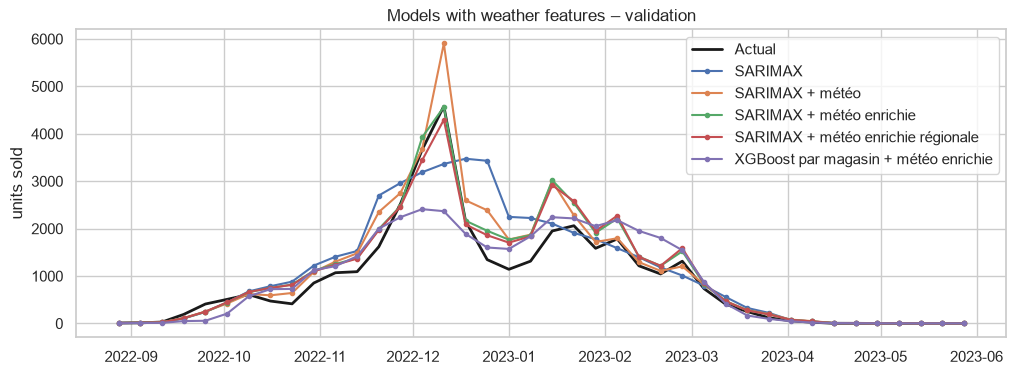

In [16]:
sarimax_rich_forecast = make_sarimax_forecast(METEO_RICH)
sarimax_rich_reg_forecast = make_sarimax_forecast(METEO_RICH_REG)
store_rich_forecast = make_store_forecast(meteo_cols=METEO_RICH)
store_lstm_rich_ab_forecast = make_store_lstm_forecast(epochs=60, meteo_cols=METEO_RICH_AB)
chronos_rich_ab_forecast = make_chronos_store_forecast(cross_learning=True, meteo_cols=METEO_RICH_AB)
optimized = {
    'SARIMAX + météo': make_sarimax_forecast(METEO_RAW),
    'SARIMAX + météo enrichie': sarimax_rich_forecast,
    'SARIMAX + météo enrichie + vacances A/B': make_sarimax_forecast(METEO_RICH_AB),
    'SARIMAX + météo enrichie régionale': sarimax_rich_reg_forecast,
    'XGBoost par magasin + météo': make_store_forecast(meteo_cols=METEO_RAW),
    'XGBoost par magasin + météo enrichie': store_rich_forecast,
    'XGBoost par magasin + météo enrichie + vacances A/B': make_store_forecast(meteo_cols=METEO_RICH_AB),
    'XGBoost par magasin + météo enrichie + pondération': make_store_forecast(meteo_cols=METEO_RICH, half_life=26),
    'LSTM global + météo': make_store_lstm_forecast(epochs=60, meteo_cols=METEO_RAW),
    'LSTM global + météo enrichie + vacances A/B': store_lstm_rich_ab_forecast,
    'Chronos-2 + cross-learning + météo enrichie + vacances A/B': chronos_rich_ab_forecast,
}
for name, fn in optimized.items():
    evaluate(name, fn)
    if name.startswith(('XGBoost', 'LSTM')):
        overfit_check(name, fn)
plot_val(['SARIMAX', 'SARIMAX + météo', 'SARIMAX + météo enrichie', 'SARIMAX + météo enrichie régionale',
          'XGBoost par magasin + météo enrichie'],
         'Models with weather features – validation')

### 8.4 Robustesse sur plusieurs folds

| Fold | Entraînement | Prévision | Modèles |
|---|---|---|---|
| **A (principal)** | sept. 2021 → août 2022 | sept. 2022 → mai 2023 | tous |
| **B (déc. → mai)** | sept. 2021 → nov. 2022 | déc. 2022 → mai 2023 | tous |
| **C (backcast)** | saison 2022-23 | sept. 2021 → mai 2022 | sans dépendance temporelle (XGBoost, LSTM) |

Les MSE de folds différents ne se comparent pas : nous regardons le **gain de chaque variante par rapport au même
modèle sans météo**, fold par fold.

In [17]:
FOLD_B_START = pd.Timestamp('2022-12-04')
folds = {
    'Fold A (principal)': (val_train, val_future),
    'Fold B (déc.→mai)': (hist[hist.index < FOLD_B_START],
                          hist[(hist.index >= FOLD_B_START) & (hist.index <= val_future.index[-1])]),
    'Fold C (backcast)': (hist[hist.index >= VAL_START], hist[hist.index < VAL_START].loc[:'2022-05-29']),
}
FAMILY_REF = {'SARIMAX': ('SARIMAX', sarimax_forecast),
              'XGBoost par magasin': ('XGBoost par magasin', store_forecast),
              'LSTM global': ('LSTM global + embedding (60 ép.)', store_lstm_short_forecast),
              'Chronos-2': ('Chronos-2 par magasin + cross-learning', chronos_cross_forecast)}
NO_BACKCAST = ('SARIMAX', 'Chronos-2')   # le fold C « prévoit le passé » : interdit aux modèles temporels
candidates = {ref: fn for ref, fn in FAMILY_REF.values()} | optimized

rows = {}
for name, fn in candidates.items():
    rows[name] = {fold: np.nan if (fold.startswith('Fold C') and name.startswith(NO_BACKCAST))
                  else metrics(f_future.sales, fn(f_train, f_future.drop(columns='sales')).clip(lower=0))['MSE']
                  for fold, (f_train, f_future) in folds.items()}
robust = pd.DataFrame(rows).T
for family, (ref_name, _) in FAMILY_REF.items():
    members = [n for n in robust.index if n.startswith(family)]
    for fold in folds:
        robust.loc[members, f'gain {fold[:6]}'] = robust.loc[members, fold] / robust.loc[ref_name, fold] - 1
robust.style.format('{:,.0f}', subset=list(folds)).format('{:+.0%}', subset=[c for c in robust if c.startswith('gain')], na_rep='–')

,Fold A (principal),Fold B (déc.→mai),Fold C (backcast),gain Fold A,gain Fold B,gain Fold C
SARIMAX,"307,184","343,230",nan,+0%,+0%,–
XGBoost par magasin,"298,265","395,256","359,991",+0%,+0%,+0%
LSTM global + embedding (60 ép.),"296,569","430,350","491,277",+0%,+0%,+0%
Chronos-2 par magasin + cross-learning,"356,046","387,264",nan,+0%,+0%,–
SARIMAX + météo,"147,116","100,332",nan,-52%,-71%,–
SARIMAX + météo enrichie,"88,189","93,325",nan,-71%,-73%,–
SARIMAX + météo enrichie + vacances A/B,"202,341","216,771",nan,-34%,-37%,–
SARIMAX + météo enrichie régionale,"82,459","85,876",nan,-73%,-75%,–
XGBoost par magasin + météo,"246,933","336,545","239,108",-17%,-15%,-34%
XGBoost par magasin + météo enrichie,"239,370","330,032","251,118",-20%,-17%,-30%


### 8.5 Conclusion des optimisations

| Modèle (MSE fold A) | Sans météo | + météo brute | + météo enrichie | + météo enrichie + vacances A/B |
|---|---|---|---|---|
| SARIMAX | ≈ 307 000 | ≈ 147 000 | **≈ 88 000** | ≈ 202 000 |
| SARIMAX, météo régionale pondérée | – | – | **≈ 82 000** | – |
| XGBoost par magasin | ≈ 298 000 | ≈ 247 000 | ≈ 239 000 | ≈ 238 000 |
| LSTM global + embedding (60 ép.) | ≈ 297 000 | ≈ 274 000 | – | ≈ 322 000 |
| Chronos-2 + cross-learning | ≈ 356 000 | – | – | ≈ 192 000 |

- **La météo est l'optimisation décisive et elle est robuste** : elle explique la variation du pic d'une année à
  l'autre (corrélation ventes × température de −0,68 en hiver), et le gain du SARIMAX + météo enrichie se confirme
  sur les folds A et B (−71 % et −73 %), celui du XGBoost par magasin sur les trois folds (−17 % à −30 %).
- **La météo enrichie corrige l'extrapolation** : avec la température brute, le SARIMAX surestimait le pic (≈ 5 900
  contre 4 582), la semaine du 11/12/2022 (−2,0 °C) étant plus froide que tout l'entraînement (min. 1,6 °C). Le
  **SARIMAX + météo enrichie** devient le meilleur modèle du projet (MSE ≈ 88 000, −78 % par rapport au naïf).
- **La météo régionale améliore encore le SARIMAX** (≈ 82 000, gain de −73 % et −75 % sur les folds A et B) : bien
  qu'elle ne s'écarte de celle de Paris que de 0,36 °C au plus, elle représente mieux le froid ressenti par l'ensemble des
  clients. Le gain supplémentaire (≈ −7 %) reste modeste.
- **Les vacances A/B n'aident pas** (neutres pour le XGBoost, nettement défavorables au SARIMAX) et **la pondération des
  semaines récentes dégrade tous les folds** : elles sont écartées.
- **Chronos-2 exploite bien les nouvelles covariables** (−46 % et −54 %) ; **le LSTM global reste instable** d'un fold
  à l'autre.
- Réserves : ces scores utilisent la météo observée et reposent sur deux saisons d'historique.

## 9. Comparaison et prévisions finales

### 9.1 Résultats de validation (sept. 2022 → mai 2023)

In [18]:
display(results_table())
overfit_table()

,MSE,RMSE,MAE,WAPE
SARIMAX + météo enrichie régionale,"82,459",287,190,20.8%
SARIMAX + météo enrichie,"88,189",297,186,20.3%
SARIMAX + météo,"147,116",384,212,23.2%
Chronos-2 + cross-learning + météo enrichie + vacances A/B,"191,719",438,296,32.3%
SARIMAX + météo enrichie + vacances A/B,"202,341",450,252,27.6%
XGBoost par magasin + météo enrichie + vacances A/B,"238,475",488,277,30.3%
XGBoost par magasin + météo enrichie,"239,370",489,277,30.3%
XGBoost par magasin + météo,"246,933",497,285,31.1%
LSTM global + météo,"274,485",524,285,31.2%
LSTM global + embedding (60 ép.),"296,569",545,302,33.0%


,MSE train,MSE validation,ratio val / train
Random Forest,"30,029","368,001",12.3
XGBoost,"7,412","371,109",50.1
LSTM,"23,154","362,768",15.7
XGBoost par magasin,"62,049","298,265",4.8
XGBoost par magasin + activité,"69,567","313,878",4.5
LSTM global + embedding,"16,343","327,890",20.1
Random Forest régularisé,"93,195","357,749",3.8
XGBoost régularisé,"62,255","319,429",5.1
LSTM régularisé,"58,458","324,968",5.6
LSTM global + embedding (60 ép.),"35,806","296,569",8.3


### 9.2 Prévisions finales 2023-2024

Les principaux modèles sont réentraînés sur tout l'historique (102 semaines, deux saisons), puis prévoient les
40 semaines du test (27/08/2023 → 26/05/2024). Les ventes réelles n'étant pas publiques, nous comparons le total prévu
et le pic ; le score Kaggle public est indiqué pour les fichiers soumis. Les modèles avec météo utilisent la météo
observée sur la période de test.

,MSE validation,Total prévu 2023-24,Semaine du pic,Pic prévu,Score Kaggle public
SARIMAX + météo enrichie régionale,"82,459","36,458",2024-01-07,"3,373",–
SARIMAX + météo enrichie,"88,189","36,394",2024-01-07,"3,342",≈ 67 000
Chronos-2 + cross-learning + météo enrichie + vacances A/B,"191,719","31,901",2023-11-26,"2,585",–
XGBoost par magasin + météo enrichie,"239,370","33,917",2023-12-03,"2,630",–
LSTM global + embedding (60 ép.),"296,569","39,147",2023-12-17,"3,917",–
XGBoost par magasin,"298,265","36,178",2023-12-10,"2,561",–
SARIMAX,"307,184","37,612",2023-12-24,"2,973",–
XGBoost régularisé,"319,429","38,230",2023-12-03,"2,549",–
Chronos-2 par magasin + cross-learning,"356,046","34,288",2023-12-03,"2,375",–
Seasonal naive,"409,124","36,582",2023-12-10,"4,582",–


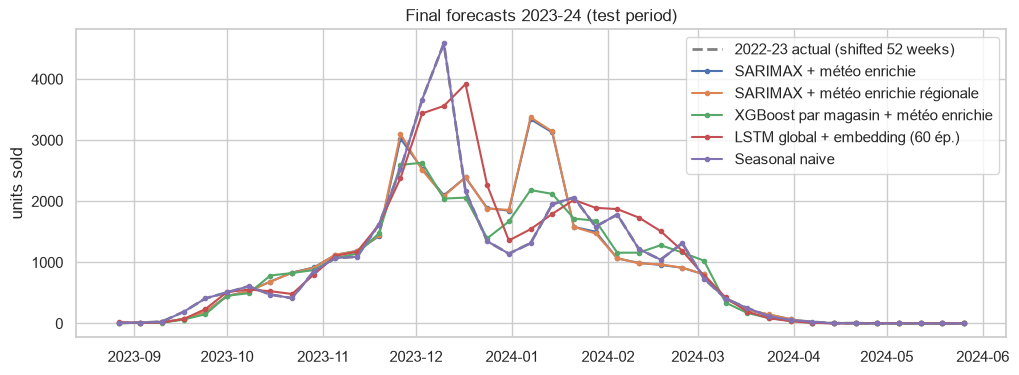

In [19]:
FINAL_MODELS = {
    'Seasonal naive': seasonal_naive,
    'SARIMAX': sarimax_forecast,
    'XGBoost régularisé': xgb_reg_forecast,
    'XGBoost par magasin': store_forecast,
    'LSTM global + embedding (60 ép.)': store_lstm_short_forecast,
    'Chronos-2 par magasin + cross-learning': chronos_cross_forecast,
    'SARIMAX + météo enrichie': sarimax_rich_forecast,
    'SARIMAX + météo enrichie régionale': sarimax_rich_reg_forecast,
    'XGBoost par magasin + météo enrichie': store_rich_forecast,
    'Chronos-2 + cross-learning + météo enrichie + vacances A/B': chronos_rich_ab_forecast,
}
KAGGLE_PUBLIC = {'SARIMAX + météo enrichie': '≈ 67 000'}   # score public communiqué par Kaggle après soumission

test_preds = {name: fn(hist, future.drop(columns='sales')).clip(lower=0) for name, fn in FINAL_MODELS.items()}
final = pd.DataFrame({name: {'MSE validation': results[name]['MSE'], 'Total prévu 2023-24': pred.sum(),
                             'Semaine du pic': pred.idxmax().date(), 'Pic prévu': pred.max(),
                             'Score Kaggle public': KAGGLE_PUBLIC.get(name, '–')}
                      for name, pred in test_preds.items()}).T.sort_values('MSE validation')
display(final.style.format({'MSE validation': '{:,.0f}', 'Total prévu 2023-24': '{:,.0f}', 'Pic prévu': '{:,.0f}'}))

fig, ax = plt.subplots()
last_season = hist.sales.loc['2022-08-28':'2023-05-28']
ax.plot(last_season.index + pd.Timedelta(weeks=52), last_season.values, color='grey', lw=2, ls='--', label='2022-23 actual (shifted 52 weeks)')
for name in ['SARIMAX + météo enrichie', 'SARIMAX + météo enrichie régionale', 'XGBoost par magasin + météo enrichie', 'LSTM global + embedding (60 ép.)', 'Seasonal naive']:
    ax.plot(test_preds[name].index, test_preds[name], marker='.', label=name)
ax.set_title('Final forecasts 2023-24 (test period)'); ax.set_ylabel('units sold'); ax.legend(); plt.show()

Les modèles avec météo prévoient pour 2023-24 un total proche de celui de 2022-23 (≈ 36 400 contre 36 582 unités),
mais un profil différent : un premier pic fin novembre (≈ 3 000) puis un second, plus haut, la semaine du 07/01/2024
(≈ 3 350), qui correspond à la vague de froid de début janvier 2024. Les modèles sans météo placent au contraire le pic
en décembre, au même endroit que les saisons passées. Le SARIMAX + météo enrichie, soumis sur Kaggle, obtient un score
public d'environ 67 000, meilleur que sa MSE de validation : il est entraîné sur deux saisons au lieu d'une, et le score
public ne porte que sur une partie des semaines du test.

### 9.3 Fichiers de soumission

- **SARIMAX + météo enrichie** (météo de Paris) et **SARIMAX + météo enrichie régionale** : meilleurs modèles du projet ;
- **LSTM global avec embedding (60 époques)** : meilleur modèle sans données externes.

In [20]:
for name, filename in [('SARIMAX + météo enrichie', 'sarimax_meteo_enrichie.csv'),
                       ('SARIMAX + météo enrichie régionale', 'sarimax_meteo_regionale.csv'),
                       ('LSTM global + embedding (60 ép.)', 'lstm_global_embedding.csv')]:
    submission = pd.DataFrame({'ID': future.week_id.values, 'TARGET': test_preds[name].values})
    assert (submission.ID.values == sample_sub.ID.values).all()
    path = Path('../submissions') / filename
    path.parent.mkdir(exist_ok=True)
    submission.to_csv(path, index=False)
    print(f'Fichier écrit : {path} ({len(submission)} lignes, total prévu = {submission.TARGET.sum():,.0f})')

Fichier écrit : ..\submissions\sarimax_meteo_enrichie.csv (40 lignes, total prévu = 36,394)
Fichier écrit : ..\submissions\sarimax_meteo_regionale.csv (40 lignes, total prévu = 36,458)
Fichier écrit : ..\submissions\lstm_global_embedding.csv (40 lignes, total prévu = 39,147)


### 9.4 Choix final

*À compléter : choix du modèle final et justification.*